In [1]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy.stats import bartlett
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder, LabelEncoder


warnings.filterwarnings('ignore')

c:\Users\user\Anaconda3\lib\site-packages\statsmodels\tools\_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


In [2]:
data = pd.read_csv('Train.csv')
test_df = pd.read_csv('Test.csv')
extra = pd.read_csv("extra_data.csv")
ss = pd.read_csv('SampleSubmission.csv')
df = data.copy()

In [3]:
df.head()

,MERCHANT_CATEGORIZED_AT,MERCHANT_NAME,MERCHANT_CATEGORIZED_AS,PURCHASE_VALUE,PURCHASED_AT,IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY,USER_AGE,USER_GENDER,USER_HOUSEHOLD,USER_INCOME,USER_ID,Transaction_ID
0,2022-05-04 10:25:50.588042+00,UONSDA CHURCH MOGERE MWAYO TITHE,Rent / Mortgage,1700,2022-05-04 13:56:00+00,False,NaN,Male,3,10000,ID_ZX4DCF4K,ID_04mk78fa
1,2021-10-25 16:18:38.586837+00,PARK N GO,Transport & Fuel,100,2021-10-24 14:12:00+00,False,25.0,Female,4,90000,ID_U9WZMGJZ,ID_04xkfb07
2,2022-05-20 14:17:30.917297+00,SAFARICOM OFFERS TUNUKIWA,Data & WiFi,20,2022-05-27 12:46:00+00,False,NaN,Male,3,10000,ID_ZX4DCF4K,ID_051urwuw
3,2022-04-12 15:59:14.139347+00,ZILLIONS CREDIT LIMITED,Loan Repayment,3800,2022-02-07 12:16:00+00,False,NaN,Male,5,252000,ID_3JA0MAFB,ID_0e1om7rz
4,2022-05-04 10:24:26.709045+00,MICHAEL MUSEMBI,Bills & Fees,60,2022-05-04 15:28:00+00,False,NaN,Male,3,10000,ID_ZX4DCF4K,ID_0kfcoawb


In [4]:
df = df.drop(["MERCHANT_CATEGORIZED_AT", "PURCHASED_AT", "USER_ID", "Transaction_ID"], axis=1)

# **1. Exploratory Data Analysis** 

## 1.1 Analyse de la forme des données

In [5]:
df.shape

(373, 8)

In [6]:
df.dtypes.value_counts()

object     3
int64      3
bool       1
float64    1
dtype: int64

<AxesSubplot:>

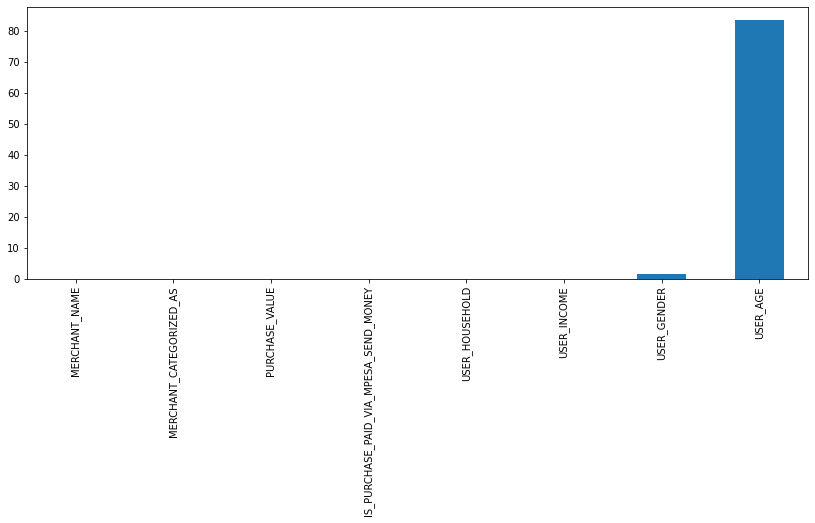

In [7]:
plt.figure(figsize=(14,5))
(df.isna().sum()*100/df.shape[0]).sort_values(ascending=True).plot.bar()

## 1.2 Analyse de fond des données

> ### Target Variable

In [8]:
df.MERCHANT_CATEGORIZED_AS.value_counts(normalize=True)*100

Bills & Fees        20.911528
Groceries           13.404826
Data & WiFi         11.528150
Miscellaneous       11.528150
Family & Friends    10.991957
Going out           10.991957
Transport & Fuel     7.774799
Shopping             5.630027
Emergency fund       3.217158
Health               1.608579
Loan Repayment       1.340483
Rent / Mortgage      0.536193
Education            0.536193
Name: MERCHANT_CATEGORIZED_AS, dtype: float64

<AxesSubplot:>

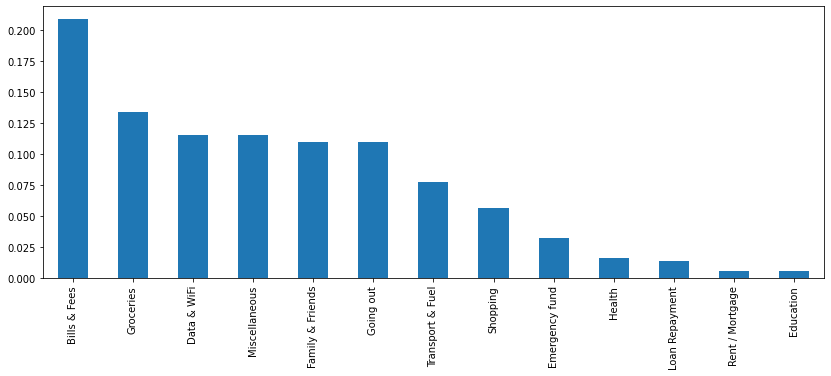

In [9]:
plt.figure(figsize=(14,5))
df.MERCHANT_CATEGORIZED_AS.value_counts(normalize=True).plot.bar()

> ### Histogramme des variables continues

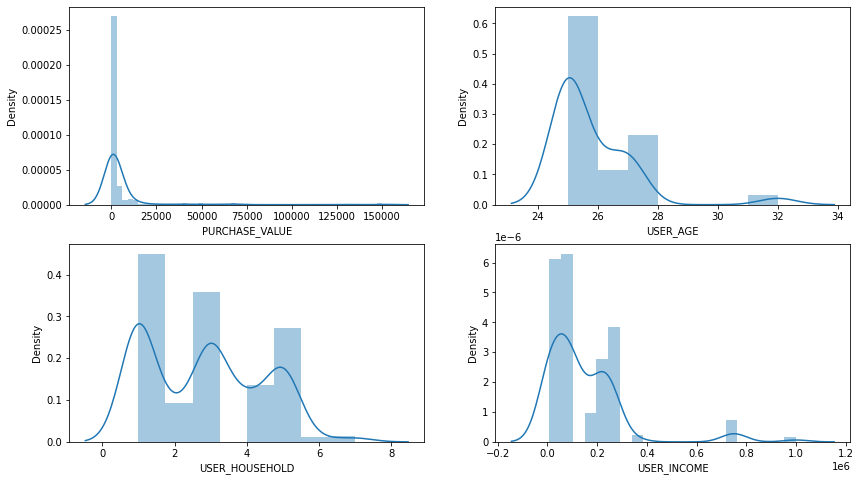

In [10]:
plt.figure(figsize=(14,8))
for i,col in enumerate(df.select_dtypes(["float","int"])):
    plt.subplot(2,2,i+1)
    sns.distplot(df[col])

In [11]:
df.USER_AGE.value_counts(normalize=True)*100

25.0    62.295082
27.0    22.950820
26.0    11.475410
32.0     3.278689
Name: USER_AGE, dtype: float64

In [12]:
df.USER_HOUSEHOLD.value_counts(normalize=True)*100

1    33.780161
3    26.809651
5    20.375335
4    10.187668
2     6.970509
7     1.072386
6     0.804290
Name: USER_HOUSEHOLD, dtype: float64

> ### Variables qualitatives

In [13]:
for i,col in enumerate(df.select_dtypes(["object","bool"])):
    if col=="MERCHANT_NAME":
        print(f" {col:<30}:{df[col].unique().shape[0]}")
    else:
        print(f" {col:<30}:{df[col].unique()}")

 MERCHANT_NAME                 :218
 MERCHANT_CATEGORIZED_AS       :['Rent / Mortgage' 'Transport & Fuel' 'Data & WiFi' 'Loan Repayment'
 'Bills & Fees' 'Miscellaneous' 'Groceries' 'Shopping' 'Family & Friends'
 'Going out' 'Emergency fund' 'Health' 'Education']
 IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY:[False  True]
 USER_GENDER                   :['Male' 'Female' nan]


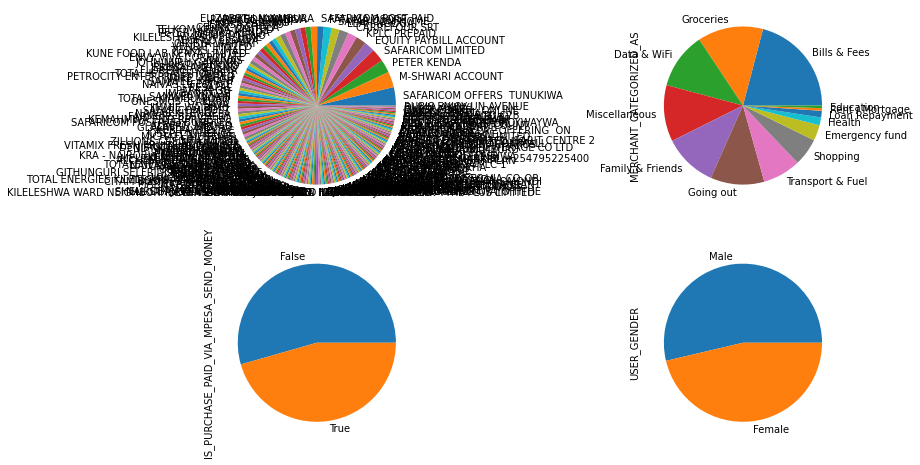

In [14]:
plt.figure(figsize=(14,8))
for i,col in enumerate(df.select_dtypes(["object","bool"])):
    plt.subplot(2,2,i+1)
    df[col].value_counts().plot.pie()

> ### Relation Target / Variables

- #### Variables qualitatives

In [15]:
pd.crosstab(df.MERCHANT_CATEGORIZED_AS, df.IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY)

IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY,False,True
MERCHANT_CATEGORIZED_AS,,
Bills & Fees,36,42
Data & WiFi,29,14
Education,2,0
Emergency fund,6,6
Family & Friends,3,38
Going out,38,3
Groceries,28,22
Health,5,1
Loan Repayment,3,2


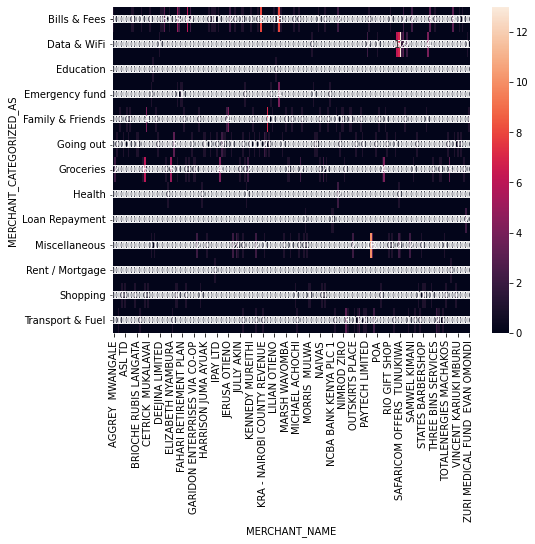

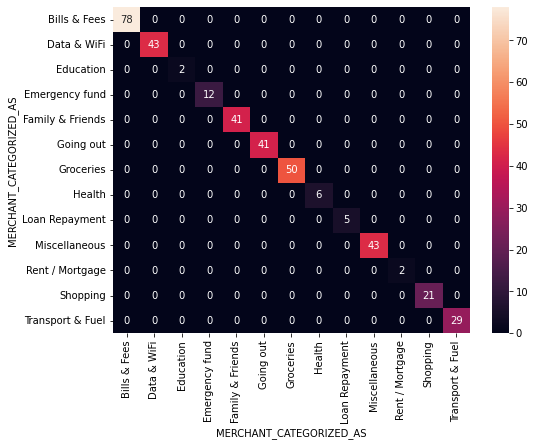

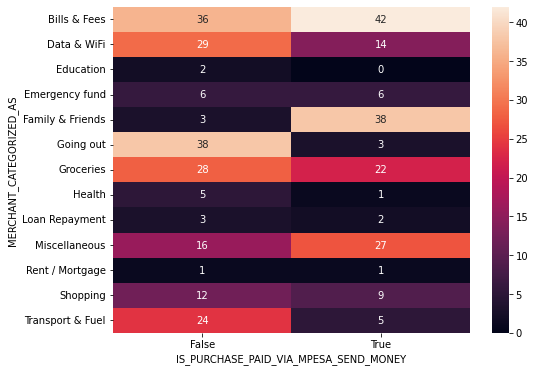

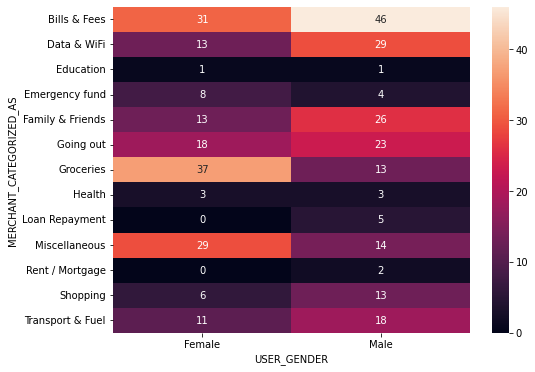

In [16]:
for i,col in enumerate(df.select_dtypes(["object","bool"])):
    plt.figure(figsize=(8,6))
    sns.heatmap(pd.crosstab(df.MERCHANT_CATEGORIZED_AS, df[col]), annot=True, fmt='d')

- #### Variables quantitatives

## 1.3 Analyse plus détaillée

> ### Relation variable/variable

- #### Entre les variables quantitatives

In [17]:
df.select_dtypes(["float","int"]).columns

Index(['PURCHASE_VALUE', 'USER_AGE', 'USER_HOUSEHOLD', 'USER_INCOME'], dtype='object')

<Figure size 864x576 with 0 Axes>

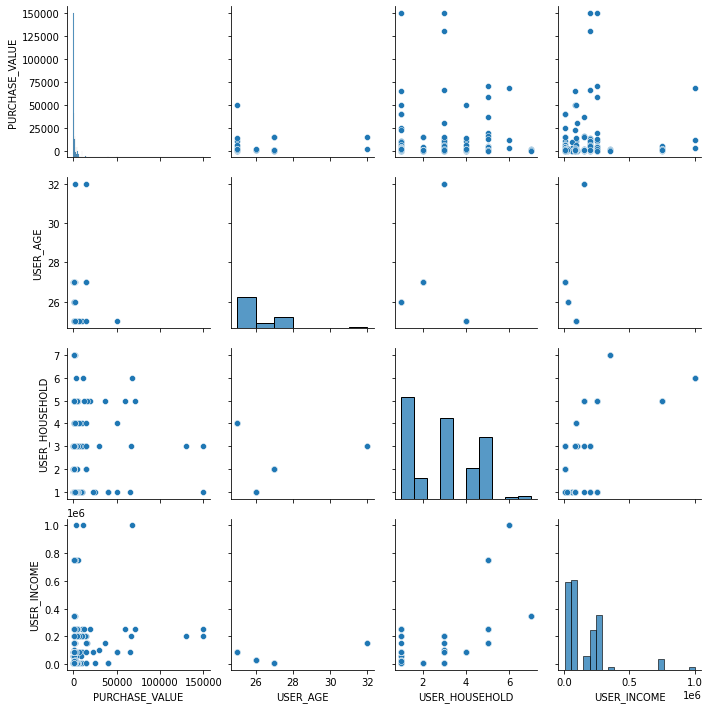

In [18]:
plt.figure(figsize=(12,8))
sns.pairplot(df.select_dtypes(["float","int"]))

<AxesSubplot:>

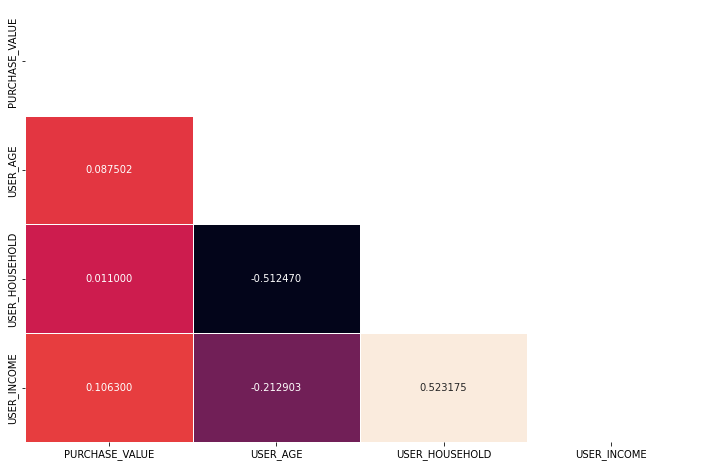

In [19]:
plt.figure(figsize=(12,8))
corr=df.select_dtypes(["float","int"]).corr()
mask=np.zeros_like(corr)
mask[np.triu_indices_from(mask)] = True
sns.heatmap(corr, annot=True, fmt="f", mask=mask, cbar=False, linewidths=1)

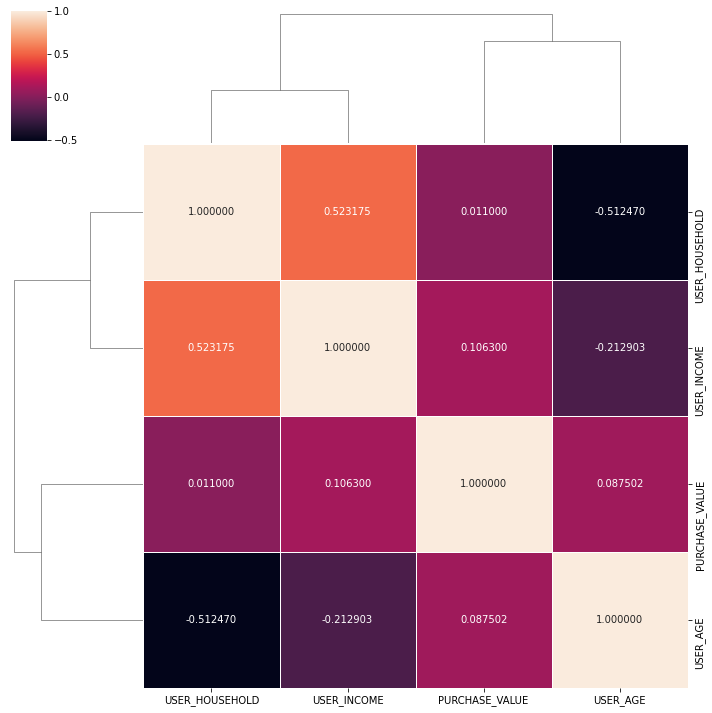

In [20]:
sns.clustermap(corr, annot=True, fmt="f", linewidths=1)

In [21]:
def cor_test(df):
    from scipy.stats.stats import pearsonr
    df.dropna(axis=0, inplace=True)
    L=df.columns
    J=[i.split("/") for i in (set(["/".join(sorted(list(set([i,j])))) for i in L for j in L if len(set([i,j]))>1]))]
    for i in J:
        cor, p=pearsonr(df[i[0]], df[i[1]])
        print(f"{i[0]} / {i[1] :-<50}: Coef:{cor} | P-value:{p}")

In [22]:
cor_test(df.select_dtypes(["float","int"]))

USER_AGE / USER_INCOME---------------------------------------: Coef:-0.21290331457917766 | P-value:0.09948102779548039
PURCHASE_VALUE / USER_HOUSEHOLD------------------------------------: Coef:0.08988724929067642 | P-value:0.4908769800582434
PURCHASE_VALUE / USER_INCOME---------------------------------------: Coef:0.11848540694301604 | P-value:0.3631045502346182
PURCHASE_VALUE / USER_AGE------------------------------------------: Coef:0.08750217202253847 | P-value:0.5024986932836377
USER_HOUSEHOLD / USER_INCOME---------------------------------------: Coef:0.8280839740924046 | P-value:1.8370138223912992e-16
USER_AGE / USER_HOUSEHOLD------------------------------------: Coef:-0.5124702141352019 | P-value:2.4191254699092806e-05


- #### Entre les variables qualitatives

**NB**: On éffectue directement les tests statistiques pour aller plus vite

In [23]:
def chi2_test(df):
    from scipy.stats import chi2_contingency
    L=df.columns
    J=[i.split("/") for i in (set(["/".join(sorted(list(set([i,j])))) for i in L for j in L if len(set([i,j]))>1]))]
    for i in J:
        table=pd.crosstab(df[i[0]], df[i[1]])
        stat, p, dof, expected = chi2_contingency(table)
        if (expected<5).sum()<expected.ravel().shape[0]*0.2:
            print(f"{i[0]} / {i[1] :-<50}: {p}")
        else:
            print(f"{i[0]} / {i[1] :-<50}: Doesn't passes the expected count assumption")

In [24]:
chi2_test(df.select_dtypes(["bool","object"]))

MERCHANT_CATEGORIZED_AS / MERCHANT_NAME-------------------------------------: Doesn't passes the expected count assumption
IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY / MERCHANT_NAME-------------------------------------: Doesn't passes the expected count assumption
MERCHANT_CATEGORIZED_AS / USER_GENDER---------------------------------------: Doesn't passes the expected count assumption
IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY / USER_GENDER---------------------------------------: 0.0057291051223607265
MERCHANT_NAME / USER_GENDER---------------------------------------: Doesn't passes the expected count assumption
IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY / MERCHANT_CATEGORIZED_AS---------------------------: Doesn't passes the expected count assumption


- #### Entre les variables qualitatives et quantitatives

Une relation m'intérèsse en particulier MERCHANT_NAME / PURCHASE_VALUE

In [25]:
A=[df.PURCHASE_VALUE[df.MERCHANT_NAME==i].to_list() for i in df.MERCHANT_NAME.unique() if df.PURCHASE_VALUE[df.MERCHANT_NAME==i].shape[0]>1]
bartlett(*A)

BartlettResult(statistic=inf, pvalue=0.0)

In [26]:
mod = ols('PURCHASE_VALUE  ~ MERCHANT_NAME',
                data=df).fit()
                
aov_table = sm.stats.anova_lm(mod, typ=2)
print(aov_table)
#aov_table.iloc[0,3]

                     sum_sq     df         F    PR(>F)
MERCHANT_NAME  6.651448e+10  217.0  1.867544  0.000022
Residual       2.544002e+10  155.0       NaN       NaN


In [27]:
from scipy.stats import shapiro
s, p = shapiro(df.PURCHASE_VALUE)
p

1.289429628651811e-35

In [28]:
def anova(df):
    I=df.select_dtypes(["float","int"])
    L=df.select_dtypes(["bool","object"])
    J=[i.split("/") for i in (set(["/".join(sorted(list(set([i,j])))) for i in I for j in L if len(set([i,j]))>1]))]
    return J

## 1.4 Feature engineering

> ### Make new variable

- ##### MERCHANT_NAME + PURCHASE_VALUE => VAR_1

In [29]:
log_PURCHASE_VALUE=np.log(df.PURCHASE_VALUE)
#sns.distplot(log_PURCHASE_VALUE)
bins=[np.quantile(log_PURCHASE_VALUE, i) for i in np.linspace(0,1,12)]
df["Var_1"]=pd.cut(log_PURCHASE_VALUE, bins).astype("object")

# **2. Pre-Processing**

In [30]:
df1=df.copy()
df1.head(2)

,MERCHANT_NAME,MERCHANT_CATEGORIZED_AS,PURCHASE_VALUE,IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY,USER_AGE,USER_GENDER,USER_HOUSEHOLD,USER_INCOME,Var_1
0,UONSDA CHURCH MOGERE MWAYO TITHE,Rent / Mortgage,1700,False,NaN,Male,3,10000,"(7.003, 7.601]"
1,PARK N GO,Transport & Fuel,100,False,25.0,Female,4,90000,"(3.99, 4.605]"


In [31]:
def imputation(df):
    return df.fillna(-999)

In [32]:
def encodage(df):
    #name_data = enc.transform(df.MERCHANT_NAME.values.reshape(-1,1))
    #bins_grade = df.Var_1.cat.as_unordered()
    #log_P_V_dummy = pd.get_dummies(bins_grade, prefix='PV')
    #df=pd.concat([df.reset_index().drop("index",axis=1),pd.DataFrame(log_P_V_dummy)], axis=1)
    #df.drop(["MERCHANT_NAME", "Var_1"], axis=1, inplace=True)
    df.drop(["USER_AGE", "IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY","USER_AGE","USER_HOUSEHOLD","USER_INCOME","USER_GENDER"], axis=1, inplace=True)
    
    cat_codes={
        False:1,
        True:0,
        "Male":1,
        "Female":0,
    }
    #df.USER_GENDER=df.USER_GENDER.map(cat_codes)
    #df.IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY=df.IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY.map(cat_codes)

    return df

In [33]:
def pre_processing(df):

    #df=imputation(df)
    df=encodage(df)

    if "MERCHANT_CATEGORIZED_AS" in df.columns.values:
        X = df.drop("MERCHANT_CATEGORIZED_AS", axis=1)
        y = df.MERCHANT_CATEGORIZED_AS
        return X,y
    else:
        X = df
        return X 


In [34]:
from sklearn.model_selection import train_test_split
train, test= train_test_split(df1, random_state=25, test_size=0.2)

In [35]:
# enc = OneHotEncoder(sparse=False,handle_unknown='ignore')
# enc.fit(train.MERCHANT_NAME.values.reshape(-1,1))

In [36]:
X_train, y_train = pre_processing(train)
X_test, y_test = pre_processing(test)

In [37]:
print(X_train.shape)
print(X_test.shape)

(298, 3)
(75, 3)


In [38]:
# pca = PCA(2)
# c=pca.fit_transform(df1)
# print(pca.explained_variance_ratio_.sum())
# lab=LabelEncoder()
# color=lab.fit_transform(df.dropna(axis=0).MERCHANT_CATEGORIZED_AS)
# plt.figure(figsize=(12,8))
# plt.scatter(c[:,0],c[:,1],c=color)

### Modélisation

In [39]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, SGDClassifier, ElasticNet, Lasso, RidgeClassifier

In [46]:
def make_model(df):
    numerical_features=df.select_dtypes(["float","int"]).columns
    categorical_features=df.select_dtypes("object").columns

    numerical_pipeline=make_pipeline(SimpleImputer(), StandardScaler())
    categorical_pipeline=make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown='ignore'))

    process=make_column_transformer((numerical_pipeline, numerical_features), (categorical_pipeline, categorical_features))

    #model=make_pipeline(process, DecisionTreeClassifier(random_state=0))
    model=make_pipeline(process, RandomForestClassifier(random_state=0))
    return model


In [47]:
model = make_model(X_train)

### Procédure d'évaluation

In [42]:
from sklearn.metrics import f1_score, confusion_matrix, classification_report, accuracy_score
from sklearn.model_selection import learning_curve

In [48]:
def evaluation(model):

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(classification_report(y_test, y_pred))

    N, train_score, val_score = learning_curve(
                                    model, X_train, y_train, cv=4,
                                    scoring='f1_micro',
                                    train_sizes=np.linspace(0.1,1,10)
                                )
    
    plt.figure(figsize=(12,8))
    plt.plot(N, train_score.mean(axis=1), label='train score')
    plt.plot(N, val_score.mean(axis=1), label="validation score")
    plt.legend()

                  precision    recall  f1-score   support

    Bills & Fees       0.47      0.41      0.44        17
     Data & WiFi       1.00      0.67      0.80         6
  Emergency fund       0.00      0.00      0.00         5
Family & Friends       0.67      0.44      0.53         9
       Going out       0.20      0.43      0.27         7
       Groceries       0.37      0.64      0.47        11
  Loan Repayment       1.00      1.00      1.00         1
   Miscellaneous       0.62      0.62      0.62         8
        Shopping       0.00      0.00      0.00         2
Transport & Fuel       0.67      0.22      0.33         9

        accuracy                           0.44        75
       macro avg       0.50      0.44      0.45        75
    weighted avg       0.50      0.44      0.44        75



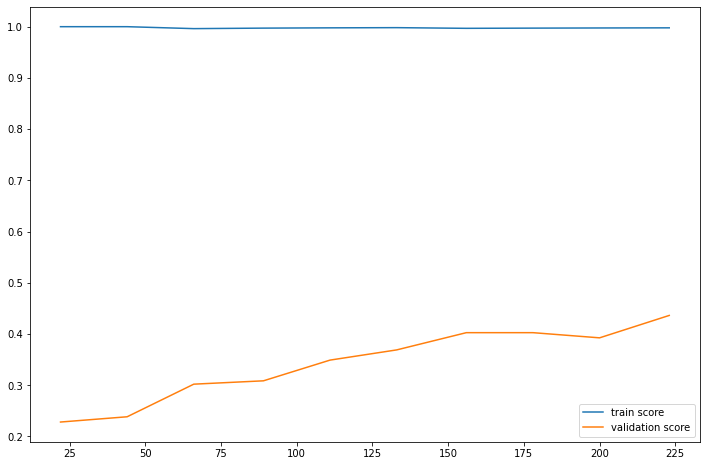

In [49]:
evaluation(model)

In [50]:
feature={f"{X_train.columns[i]}":j for i,j in enumerate(model._final_estimator.feature_importances_) if j>0}
feature_importance_pd=pd.DataFrame(feature.values(), index=feature.keys(), columns=["Importance"])
plt.figure(figsize=(12,5))
sns.barplot(feature_importance_pd.index, feature_importance_pd.Importance)
plt.xticks(rotation=90)

plt.suptitle("Feature Importance", fontsize=18, font="arial")

IndexError: index 3 is out of bounds for axis 0 with size 3

### Submission

In [ ]:
def submission(df, enc):
    df=df[df1.drop("MERCHANT_CATEGORIZED_AS", axis=1).columns]
    X_test = pre_processing(df, enc)
    predictions_proba = model.predict_proba(X_test)
    print(predictions_proba[0])
    ss.iloc[:,1:]=predictions_proba

    ss.to_csv("submission_1.csv", index=False)